In [85]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report
from yellowbrick.classifier import ConfusionMatrix

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# Loading the dataset


In [86]:
df = pd.read_csv("./milknew.csv")

In [87]:
df.head()

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,high
1,6.6,36,0,1,0,1,253,high
2,8.5,70,1,1,1,1,246,low
3,9.5,34,1,1,0,1,255,low
4,6.6,37,0,0,0,0,255,medium


In [88]:
df.describe()

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour
count,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000
mean,6.630123,44.226629,0.546742,0.432483,0.671388,0.491029,251.840415
std,1.399679,10.098364,0.498046,0.495655,0.469930,0.500156,4.307424
min,3.000000,34.000000,0.000000,0.000000,0.000000,0.000000,240.000000
25%,6.500000,38.000000,0.000000,0.000000,0.000000,0.000000,250.000000
50%,6.700000,41.000000,1.000000,0.000000,1.000000,0.000000,255.000000
75%,6.800000,45.000000,1.000000,1.000000,1.000000,1.000000,255.000000
max,9.500000,90.000000,1.000000,1.000000,1.000000,1.000000,255.000000


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1059 entries, 0 to 1058
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   pH          1059 non-null   float64
 1   Temprature  1059 non-null   int64  
 2   Taste       1059 non-null   int64  
 3   Odor        1059 non-null   int64  
 4   Fat         1059 non-null   int64  
 5   Turbidity   1059 non-null   int64  
 6   Colour      1059 non-null   int64  
 7   Grade       1059 non-null   object 
dtypes: float64(1), int64(6), object(1)
memory usage: 66.3+ KB


In [90]:
df.isnull().sum()

pH            0
Temprature    0
Taste         0
Odor          0
Fat           0
Turbidity     0
Colour        0
Grade         0
dtype: int64

In [91]:
df.replace({'Grade':{'low':0,'medium': 1 ,'high':2}},inplace=True)

In [92]:
df.head()

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,2
1,6.6,36,0,1,0,1,253,2
2,8.5,70,1,1,1,1,246,0
3,9.5,34,1,1,0,1,255,0
4,6.6,37,0,0,0,0,255,1


# Feature Scaling

In [93]:
x = df.drop('Grade', axis=1)
y = df['Grade']

In [94]:
x

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour
0,6.6,35,1,0,1,0,254
1,6.6,36,0,1,0,1,253
2,8.5,70,1,1,1,1,246
3,9.5,34,1,1,0,1,255
4,6.6,37,0,0,0,0,255
...,...,...,...,...,...,...,...
1054,6.7,45,1,1,0,0,247
1055,6.7,38,1,0,1,0,255
1056,3.0,40,1,1,1,1,255
1057,6.8,43,1,0,1,0,250


In [95]:
y

0       2
1       2
2       0
3       0
4       1
       ..
1054    1
1055    2
1056    0
1057    2
1058    0
Name: Grade, Length: 1059, dtype: int64

# Data Splitting

In [96]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print ('Train set:', x_train.shape, y_train.shape)
print ('Validation set:', x_test.shape,  y_test.shape)

Train set: (847, 7) (847,)
Validation set: (212, 7) (212,)


# KNN Classifier

In [97]:
knn=KNeighborsClassifier(n_neighbors=10)
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=10)

In [98]:
y_predict_knn = knn.predict(x_test)

Accuracy

In [99]:
accuracy_knn=knn.score(x_test,y_test)
print(accuracy_score(y_test,y_predict_knn))
print("KNN model accuracy(in %):{:.2f}%".format(accuracy_knn*100))

0.9858490566037735
KNN model accuracy(in %):98.58%


Classification Report

In [100]:
print(classification_report(y_test, y_predict_knn))


              precision    recall  f1-score   support

           0       1.00      0.97      0.99        78
           1       0.98      0.99      0.98        86
           2       0.98      1.00      0.99        48

    accuracy                           0.99       212
   macro avg       0.99      0.99      0.99       212
weighted avg       0.99      0.99      0.99       212



In [101]:
classes = ['0', '1', '2']

Confusion Matrix

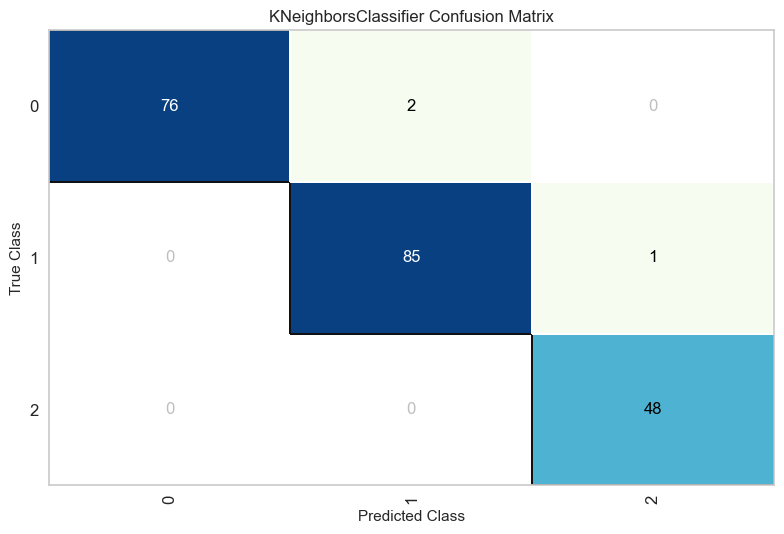

<Axes: title={'center': 'KNeighborsClassifier Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [102]:

knn_cm = ConfusionMatrix(knn, classes=classes, cmap='GnBu')

knn_cm.fit(x_train, y_train)
knn_cm.score(x_test, y_test)
knn_cm.show()

# Decision Tree

In [103]:
dt=DecisionTreeClassifier(criterion="entropy",random_state=0)
dt.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

Accuracy

In [104]:
y_pred_dt=dt.predict(x_test)
accuracy_tree=accuracy_score(y_test,y_pred_dt)
print("Decision Tree model accuracy(in %):{:.2f}%".format(accuracy_tree*100))

Decision Tree model accuracy(in %):99.06%


Classification Report

In [105]:
print(classification_report(y_test, y_pred_dt))


              precision    recall  f1-score   support

           0       1.00      0.99      0.99        78
           1       0.99      1.00      0.99        86
           2       0.98      0.98      0.98        48

    accuracy                           0.99       212
   macro avg       0.99      0.99      0.99       212
weighted avg       0.99      0.99      0.99       212



Confusion Matrix

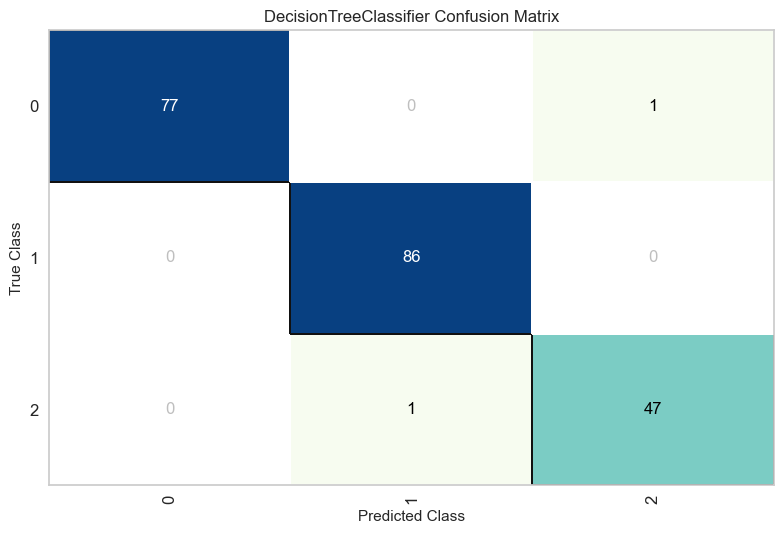

<Axes: title={'center': 'DecisionTreeClassifier Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [106]:
dt_cm = ConfusionMatrix(dt, classes=classes, cmap='GnBu')

dt_cm.fit(x_train, y_train)
dt_cm.score(x_test, y_test)
dt_cm.show()

# Random Forest Classifier

In [107]:
rf=RandomForestClassifier(n_estimators=10,criterion='entropy')
rf.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', n_estimators=10)

Accuracy

In [108]:
y_pred_rf=rf.predict(x_test)
accuracy_forest=accuracy_score(y_test,y_pred_rf)
print("Random Forest model accuracy(in %):{:.2f}%".format(accuracy_forest*100))

Random Forest model accuracy(in %):99.53%


Classification Report

In [109]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99        78
           1       1.00      1.00      1.00        86
           2       0.98      1.00      0.99        48

    accuracy                           1.00       212
   macro avg       0.99      1.00      0.99       212
weighted avg       1.00      1.00      1.00       212



Confusion Matrix

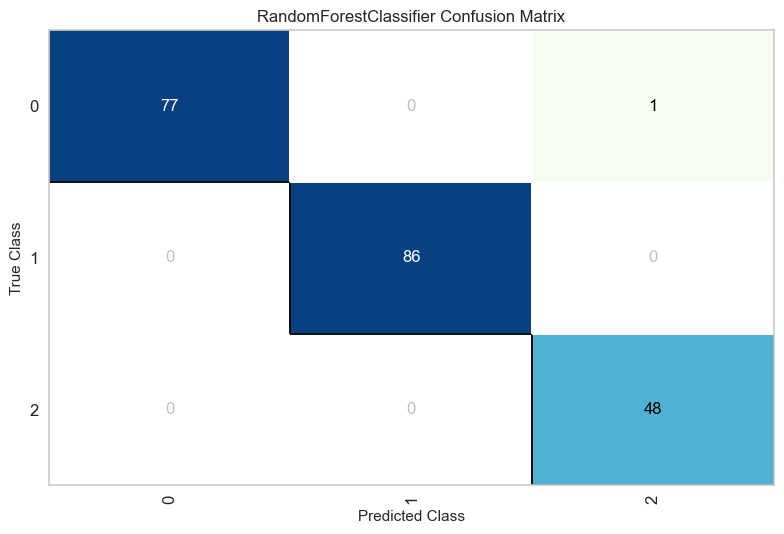

<Axes: title={'center': 'RandomForestClassifier Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [110]:
rf_cm = ConfusionMatrix(rf, classes=classes, cmap='GnBu')

rf_cm.fit(x_train, y_train)
rf_cm.score(x_test, y_test)
rf_cm.show()

# Logistic Regression

In [111]:
LR = LogisticRegression()
LR.fit(x_train,y_train)

LogisticRegression()

In [112]:
y_pred_lr = LR.predict(x_test)

Accuracy

In [113]:
accuracy_logistic=accuracy_score(y_test,y_pred_lr)
print("Logistic Regression model accuracy(in %):{:.4f}%".format(accuracy_logistic*100))

Logistic Regression model accuracy(in %):69.8113%


Classification Report

In [114]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.67      0.77      0.72        78
           1       0.77      0.85      0.81        86
           2       0.54      0.31      0.39        48

    accuracy                           0.70       212
   macro avg       0.66      0.64      0.64       212
weighted avg       0.68      0.70      0.68       212



Confusion Matrix

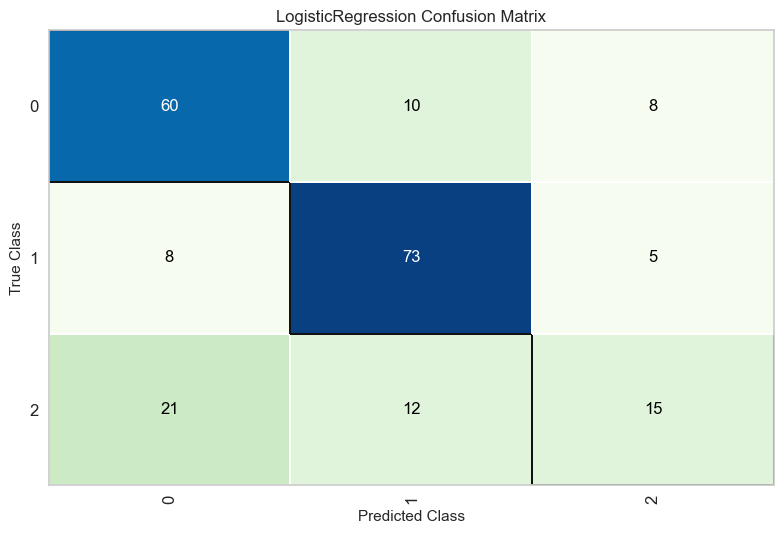

<Axes: title={'center': 'LogisticRegression Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [115]:
lr_cm = ConfusionMatrix(LR, classes=classes, cmap='GnBu')

lr_cm.fit(x_train, y_train)
lr_cm.score(x_test, y_test)
lr_cm.show()

# SVM Classifier

In [116]:
svc=SVC()
svc.fit(x_train,y_train)

SVC()

Accuracy

In [117]:
y_pred_svc=svc.predict(x_test)
accuracy_svc=accuracy_score(y_test,y_pred_svc)
print("SVM model accuracy(in %):{:.4f}%".format(accuracy_svc*100))

SVM model accuracy(in %):56.6038%


Classification Report

In [118]:
print(classification_report(y_test, y_pred_svc))

              precision    recall  f1-score   support

           0       0.71      0.53      0.60        78
           1       0.51      0.92      0.66        86
           2       0.00      0.00      0.00        48

    accuracy                           0.57       212
   macro avg       0.41      0.48      0.42       212
weighted avg       0.47      0.57      0.49       212



Confusion Matrix

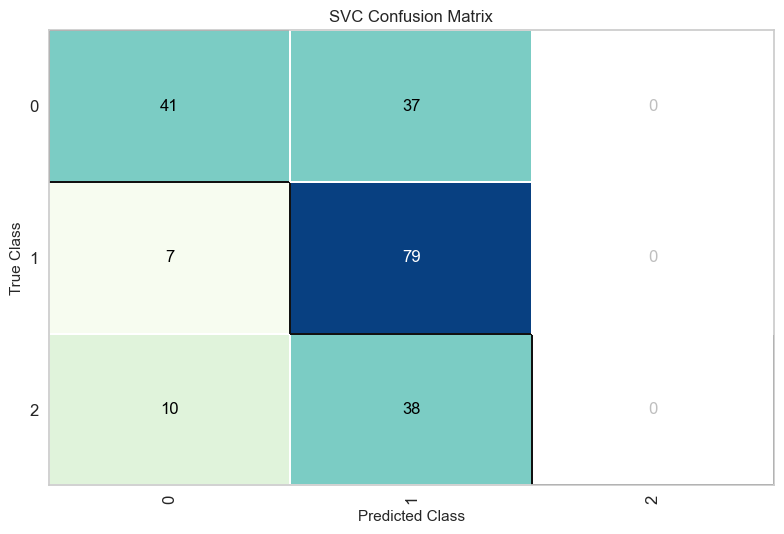

<Axes: title={'center': 'SVC Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [119]:
svc_cm = ConfusionMatrix(svc, classes=classes, cmap='GnBu')

svc_cm.fit(x_train, y_train)
svc_cm.score(x_test, y_test)
svc_cm.show()

# Comparison of Classifiers

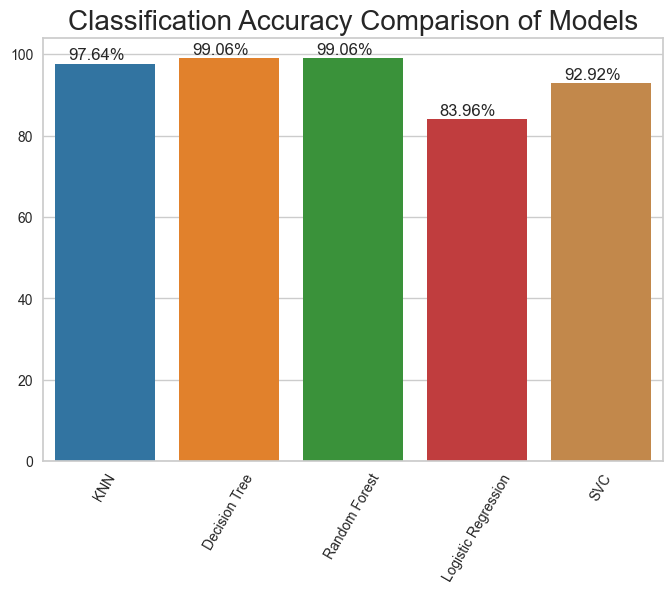

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt

# Data
models = ['KNN', 'Decision Tree', 'Random Forest', 'Logistic Regression', 'SVC']
scores = [97.64,99.06,99.06,83.96,92.92]

# Define custom colors for each bar
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#d68837']  # Example colors

# Plot
ax = sns.barplot(x=models, y=scores, palette=colors)
ax.set_title('Classification Accuracy Comparison of Models', fontsize=20)

# Rotate x-axis labels
for item in ax.get_xticklabels():
    item.set_rotation(60)

# Annotate bars with their values
for p in ax.patches:
    ax.annotate('{:.2f}%'.format(p.get_height()), (p.get_x() + 0.1, p.get_height() + 1))

plt.show()


# Prediction using Random Forest Classifier

In [121]:
df

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,2
1,6.6,36,0,1,0,1,253,2
2,8.5,70,1,1,1,1,246,0
3,9.5,34,1,1,0,1,255,0
4,6.6,37,0,0,0,0,255,1
...,...,...,...,...,...,...,...,...
1054,6.7,45,1,1,0,0,247,1
1055,6.7,38,1,0,1,0,255,2
1056,3.0,40,1,1,1,1,255,0
1057,6.8,43,1,0,1,0,250,2


In [122]:
input_data = (9.5,34,1,1,0,1,255)

# change the input data to a numpy array
input_data_as_numpy_array= np.asarray(input_data)

# reshape the numpy array as we are predicting for only on instance
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

inp = StandardScaler().fit_transform(input_data_reshaped)

prediction1 = rf.predict(input_data_reshaped)
print(prediction1)


[0]


In [123]:
input_data = (6.6,38,0,0,0,0,255)

# change the input data to a numpy array
input_data_as_numpy_array= np.asarray(input_data)

# reshape the numpy array as we are predicting for only on instance
input_data_reshaped1 = input_data_as_numpy_array.reshape(1,-1)

inp = StandardScaler().fit_transform(input_data_reshaped1)

prediction2 = rf.predict(input_data_reshaped1)
print(prediction2)


[1]


In [127]:
input_data = (6.7,38,1,0,1,0,255)

# change the input data to a numpy array
input_data_as_numpy_array= np.asarray(input_data)

# reshape the numpy array as we are predicting for only on instance
input_data_reshaped2 = input_data_as_numpy_array.reshape(1,-1)

inp = StandardScaler().fit_transform(input_data_reshaped2)

prediction3 = rf.predict(input_data_reshaped2)
print(prediction3)


[2]


In [ ]:
import pickle
filename='milk_prediction_model.pkl'
pickle.dump(rf,open(filename,'wb'))